In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
!wget -q https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [ ]:
import zipfile
import os

zip_file = "/content/archive (1).zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("/content/") # Extract to /content directory

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

print("Contents of /content/ after extraction:")
for item in os.listdir("/content/"):
    item_path = os.path.join("/content/", item)
    if os.path.isdir(item_path):
        print(f"Directory: {item}/")
    else:
        print(f"File: {item}")


Contents of /content/ after extraction:
Directory: .config/
File: archive (1).zip
Directory: drive/
Directory: train_zip/
Directory: test_zip/
Directory: sample_data/


In [ ]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

SOURCE_DIR = "/content/train_zip/train"  # Where the mixed images and xmls are
TARGET_DIR_FOR_TFDS = "/content/train_zip/train_processed" # New directory with class subfolders

# Create the target directory if it doesn't exist
if not os.path.exists(TARGET_DIR_FOR_TFDS):
    os.makedirs(TARGET_DIR_FOR_TFDS)

# Restructure the dataset
for filename in os.listdir(SOURCE_DIR):
    if filename.endswith(('.jpg', '.jpeg', '.png', '.bmp', '.gif')):
        # Extract class name from filename (e.g., 'apple_1.jpg' -> 'apple')
        class_name = filename.split('_')[0]

        # Create class directory if it doesn't exist
        class_path = os.path.join(TARGET_DIR_FOR_TFDS, class_name)
        if not os.path.exists(class_path):
            os.makedirs(class_path)

        # Move the image file to its class directory
        src_path = os.path.join(SOURCE_DIR, filename)
        dst_path = os.path.join(class_path, filename)
        os.rename(src_path, dst_path)

# Now set DATASET_PATH to the newly structured directory
DATASET_PATH = TARGET_DIR_FOR_TFDS

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names

print("Classes:", class_names)

Found 240 files belonging to 4 classes.
Using 192 files for training.
Found 240 files belonging to 4 classes.
Using 48 files for validation.
Classes: ['apple', 'banana', 'mixed', 'orange']


In [ ]:
import os

print("Contents of train_zip:")
print(os.listdir("/content/train_zip"))

Contents of train_zip:
['train']


In [ ]:
print("Contents inside train:")
print(os.listdir("/content/train_zip/train"))

Contents inside train:
['orange_62.xml', 'banana_7.jpg', 'mixed_16.jpg', 'banana_51.xml', 'mixed_9.jpg', 'apple_42.jpg', 'orange_22.xml', 'mixed_6.jpg', 'mixed_1.jpg', 'apple_59.xml', 'apple_64.xml', 'orange_4.xml', 'orange_43.xml', 'apple_42.xml', 'orange_53.xml', 'apple_54.xml', 'orange_73.jpg', 'orange_18.jpg', 'apple_45.xml', 'orange_29.xml', 'apple_4.xml', 'orange_35.xml', 'apple_19.jpg', 'mixed_12.jpg', 'banana_73.jpg', 'orange_35.jpg', 'apple_64.jpg', 'banana_37.xml', 'orange_31.jpg', 'apple_44.jpg', 'banana_46.jpg', 'mixed_8.jpg', 'mixed_11.jpg', 'orange_33.jpg', 'orange_72.jpg', 'banana_11.xml', 'orange_26.xml', 'orange_2.xml', 'mixed_5.jpg', 'orange_11.xml', 'banana_44.xml', 'banana_64.xml', 'orange_76.xml', 'banana_48.xml', 'banana_42.xml', 'orange_54.jpg', 'apple_65.jpg', 'apple_25.xml', 'banana_43.xml', 'orange_8.jpg', 'apple_1.xml', 'banana_40.xml', 'orange_19.jpg', 'apple_5.xml', 'banana_55.xml', 'orange_32.jpg', 'banana_68.xml', 'banana_3.xml', 'banana_53.jpg', 'mixed_1

In [ ]:
import os

base_path = "/content/train_zip"

print("Main folder:")
print(os.listdir(base_path))

print("\nAll folders inside train_zip:")

for root, dirs, files in os.walk(base_path):
    print("PATH:", root)
    print("FOLDERS:", dirs)
    print("NUMBER OF FILES:", len(files))
    print("-" * 50)

Main folder:
['train_processed', 'train']

All folders inside train_zip:
PATH: /content/train_zip
FOLDERS: ['train_processed', 'train']
NUMBER OF FILES: 0
--------------------------------------------------
PATH: /content/train_zip/train_processed
FOLDERS: ['apple', 'mixed', 'orange', 'banana']
NUMBER OF FILES: 0
--------------------------------------------------
PATH: /content/train_zip/train_processed/apple
FOLDERS: []
NUMBER OF FILES: 75
--------------------------------------------------
PATH: /content/train_zip/train_processed/mixed
FOLDERS: []
NUMBER OF FILES: 20
--------------------------------------------------
PATH: /content/train_zip/train_processed/orange
FOLDERS: []
NUMBER OF FILES: 72
--------------------------------------------------
PATH: /content/train_zip/train_processed/banana
FOLDERS: []
NUMBER OF FILES: 73
--------------------------------------------------
PATH: /content/train_zip/train
FOLDERS: []
NUMBER OF FILES: 240
-------------------------------------------------

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

DATASET_PATH = "/content/train_zip/train_processed"

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names

print("Classes:", class_names)

Found 240 files belonging to 4 classes.
Using 192 files for training.
Found 240 files belonging to 4 classes.
Using 48 files for validation.
Classes: ['apple', 'banana', 'mixed', 'orange']


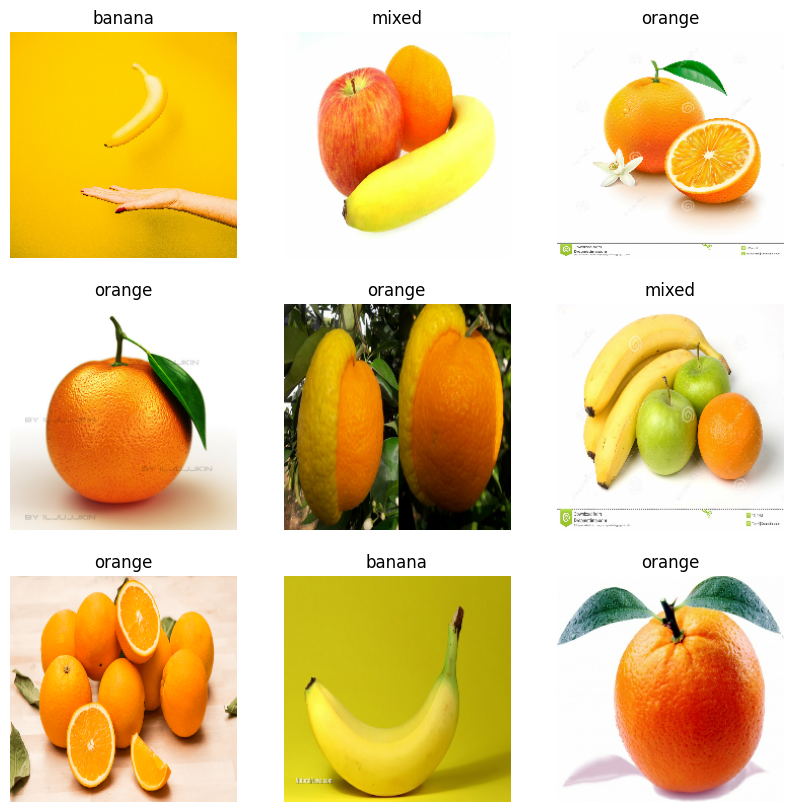

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

print("Dataset preparation completed!")

Dataset preparation completed!


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax")
])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.3594 - loss: 1.4926 - val_accuracy: 0.3958 - val_loss: 1.1537
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.4740 - loss: 1.1859 - val_accuracy: 0.5417 - val_loss: 0.9913
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.5365 - loss: 0.9708 - val_accuracy: 0.6458 - val_loss: 0.8205
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.6146 - loss: 0.8378 - val_accuracy: 0.7083 - val_loss: 0.8013
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.6302 - loss: 0.8077 - val_accuracy: 0.6667 - val_loss: 0.7810
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.7135 - loss: 0.7220 - val_accuracy: 0.6875 - val_loss: 0.7139
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.7188 - loss: 0.6678 - val_accuracy: 0.7292 - val_loss: 0.6584
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.7396 - loss: 0.6524 - val_accuracy: 0.6667 - val_loss: 0.7359
Epoch 9/

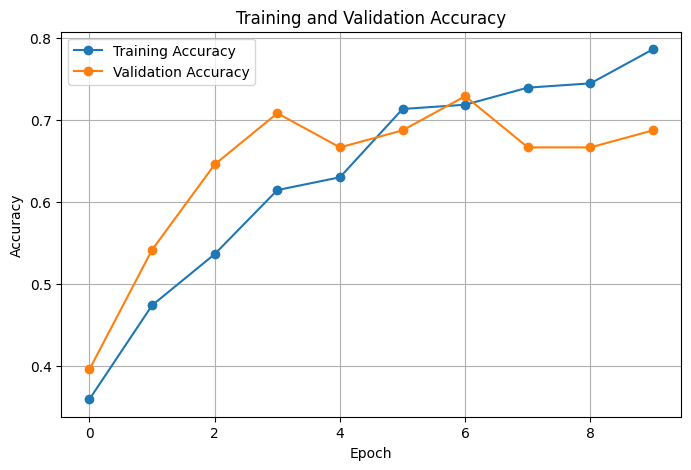

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

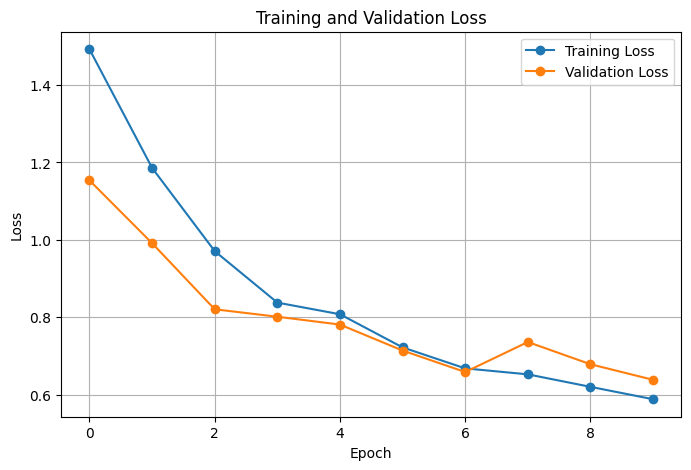

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
loss, accuracy = model.evaluate(validation_dataset)

print("Validation Loss:", round(loss, 4))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.6875 - loss: 0.6382
Validation Loss: 0.6382
Validation Accuracy: 68.75 %


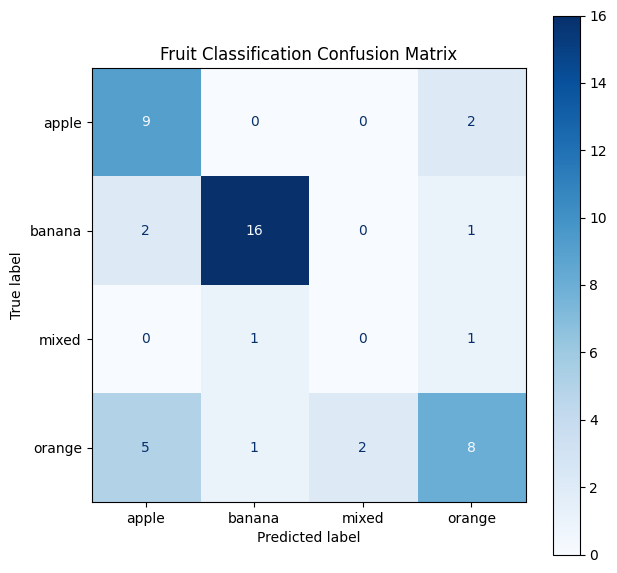

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, cmap="Blues")

plt.title("Fruit Classification Confusion Matrix")
plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving apple.jpg to apple.jpg


In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

image_path = list(uploaded.keys())[0]

img = load_img(image_path, target_size=(224, 224))

img_array = img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

predictions = model.predict(img_array, verbose=0)

predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

print("Predicted Fruit:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

Predicted Fruit: apple
Confidence: 67.88 %


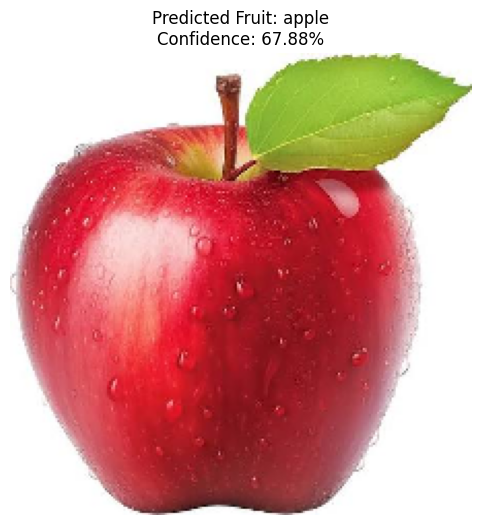

In [ ]:
plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.title(
    f"Predicted Fruit: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()

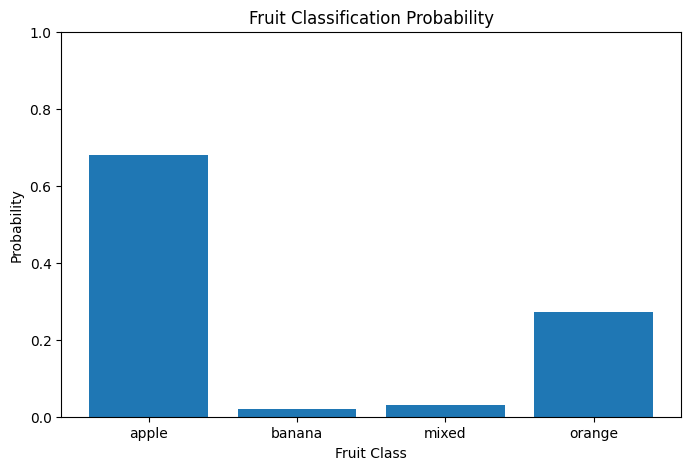

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(class_names, predictions[0])

plt.xlabel("Fruit Class")
plt.ylabel("Probability")
plt.title("Fruit Classification Probability")

plt.ylim(0, 1)

plt.show()

In [ ]:
model.save("fruit_classification_model.keras")

print("Model saved successfully!")

Model saved successfully!
